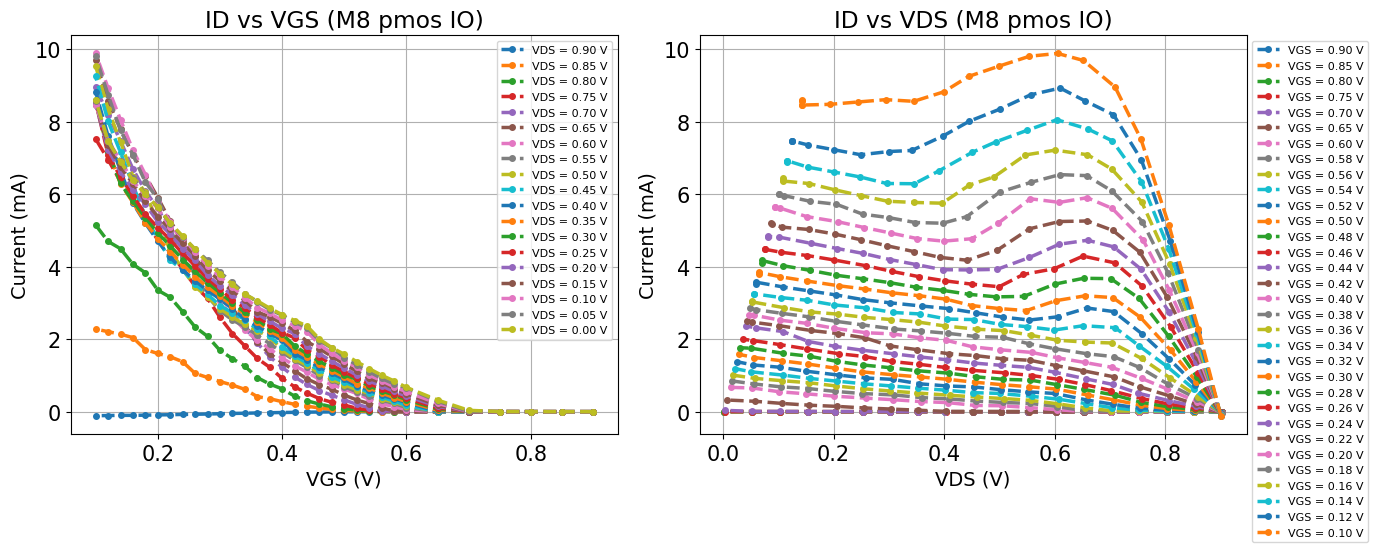

In [9]:
import numpy as np 
import matplotlib.pyplot as plt 

def plot_ax(ax, x, y, *args, xlabel=None, ylabel=None, title=None, legend_outside=False, **kwargs):
    ax.plot(x, y, *args, **kwargs)
    ax.grid(True)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if "label" in kwargs and kwargs["label"] != None: 
        if legend_outside:
            ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
        else:
            ax.legend() 

plt.rcParams.update({'figure.figsize': (8, 5),
                         'font.size': 14,
                         'lines.markersize': 8,
                         'lines.linewidth': 2.5,
                         'xtick.labelsize': 15,
                         'ytick.labelsize': 15,
                         'errorbar.capsize': 2})


file_path = r'C:\\Users\\andrish\\Downloads/4K_M8_32u_30n_pmos_ulvt_1006_140657.npz' 
type_xtor = 'pmos'
xtor_name = 'M8'
volt = 'IO'


file = np.load(file_path) 
all_VGS=file['all_VGS']
all_IDS=file['all_IDS']
all_VDS=file['all_VDS']
all_VDS_meas=file['all_VDS_meas']
all_VGS_meas=file['all_VGS_meas']

idx = np.where(all_VGS >= 0.1)
all_VGS_arr = np.array(all_VGS)[idx]
all_VDS_arr = np.array(all_VDS)
IDS_mean = (-1)**int(type_xtor=='nmos')*np.array(all_IDS).mean(axis=-1) * 1e3     # (n_VGS, n_VDS), in mA

# ID vs VGS: one curve per VDS
fig, ax = plt.subplots(figsize=(14, 5.5), ncols=2)
for j, vds in enumerate(all_VDS_arr):
    plot_ax(ax[0], np.array(all_VGS)[idx], IDS_mean[:, j][idx], '.--', label=f'VDS = {vds:.2f} V', 
            xlabel='VGS (V)', ylabel='Current (mA)', title=f'ID vs VGS ({xtor_name} {type_xtor} {volt})')


# ID vs VDS: one curve per VGS
for i, vgs in enumerate(all_VGS_arr):
    plot_ax(ax[1], all_VDS_meas[i], IDS_mean[i, :], '.--', label=f'VGS = {vgs:.2f} V', 
            xlabel='VDS (V)', ylabel='Current (mA)', title=f'ID vs VDS ({xtor_name} {type_xtor} {volt})')

ax[0].legend(fontsize=8); ax[1].legend(bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
all_VGS_meas

array([0.88751811, 0.84372127, 0.81175643, 0.75958091, 0.69952834,
       0.67253804, 0.61245805, 0.5976758 , 0.55489802, 0.5458886 ,
       0.49815002, 0.49923706, 0.45768666, 0.44231856, 0.4583362 ,
       0.41884819, 0.39251038, 0.36165142, 0.34957373, 0.35318267,
       0.32396057, 0.28877032, 0.26451555, 0.27241728, 0.23691833,
       0.19813162, 0.18335386, 0.15985626, 0.13632979, 0.11078411,
       0.09475331, 0.06883876, 0.05633082, 0.06633358])